<a href="https://colab.research.google.com/github/azkas268-code/liver-tumor-thesis./blob/main/Liver_Tumor_Thesis_ipynb_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!nvidia-smi

Wed Oct 21 17:35:34 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   39C    P8             11W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

 STEP 1: Setup

In [7]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

BASE = '/content/drive/MyDrive/thesis'

folders = [
    'raw/LiTS',          # original LiTS scans
    'raw/IRCADb',        # original 3D-IRCADb scans
    'processed/LiTS',    # cleaned LiTS scans
    'processed/IRCADb',  # cleaned IRCADb scans
    'code',              # your python files
    'checkpoints',       # saved trained models
    'results/csv',       # score tables
    'results/figures',   # pictures for your thesis
]

for f in folders:
    os.makedirs(os.path.join(BASE, f), exist_ok=True)

print("Folders created:")
for f in folders:
    print("  ", os.path.join(BASE, f))

Folders created:
   /content/drive/MyDrive/thesis/raw/LiTS
   /content/drive/MyDrive/thesis/raw/IRCADb
   /content/drive/MyDrive/thesis/processed/LiTS
   /content/drive/MyDrive/thesis/processed/IRCADb
   /content/drive/MyDrive/thesis/code
   /content/drive/MyDrive/thesis/checkpoints
   /content/drive/MyDrive/thesis/results/csv
   /content/drive/MyDrive/thesis/results/figures


In [3]:
!pip install -q monai nibabel SimpleITK pydicom kaggle

In [ ]:
import torch, monai, nibabel, SimpleITK, pydicom, cv2, numpy as np
from monai.networks.nets import SegResNet

print("PyTorch version :", torch.__version__)
print("MONAI version   :", monai.__version__)
print("GPU available   :", torch.cuda.is_available())
print("GPU name        :", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "NO GPU")

# Build the same model as the base paper (SegResNet_2335)
model = SegResNet(
    spatial_dims=3,             # 3D model
    in_channels=1,              # 1 input = CT scan
    out_channels=3,             # 3 outputs = background, liver, tumor
    init_filters=8,             # starts with 8 channels (8 -> 16 -> 32 -> 64)
    blocks_down=(2, 3, 3, 5),   # this is the "2335" in the paper's name
    blocks_up=(1, 1, 1),
    norm=("GROUP", {"num_groups": 8}),
    upsample_mode="nontrainable",  # trilinear upsampling, same as the paper
)

params = sum(p.numel() for p in model.parameters()) / 1e6
print(f"Model parameters: {params:.2f} million  (paper says about 1.5 million)")

# Test with a fake CT patch
x = torch.zeros(1, 1, 64, 64, 64)
y = model(x)
print("Input shape :", tuple(x.shape))
print("Output shape:", tuple(y.shape), " -> 3 channels = background, liver, tumor")
print("\n✅ STEP 1 COMPLETE!")

PyTorch version : 2.11.0+cu130
MONAI version   : 1.6.1
GPU available   : True
GPU name        : Tesla T4
Model parameters: 1.47 million  (paper says about 1.5 million)
Input shape : (1, 1, 64, 64, 64)
Output shape: (1, 3, 64, 64, 64)  -> 3 channels = background, liver, tumor

✅ STEP 1 COMPLETE!


# STEP 2: Download LiTS dataset

In [8]:
import os, shutil

KAGGLE_IN_DRIVE = '/content/drive/MyDrive/thesis/kaggle.json'
os.makedirs('/root/.kaggle', exist_ok=True)

if os.path.exists(KAGGLE_IN_DRIVE):
    # Second time onwards: take the key from Drive automatically
    shutil.copy(KAGGLE_IN_DRIVE, '/root/.kaggle/kaggle.json')
    print("✅ Found kaggle.json in Drive, no upload needed")
else:
    # First time: upload it from your computer
    from google.colab import files
    print("Please click 'Choose Files' and select your kaggle.json file")
    uploaded = files.upload()
    name = list(uploaded.keys())[0]
    shutil.copy(name, '/root/.kaggle/kaggle.json')
    shutil.copy(name, KAGGLE_IN_DRIVE)   # save a copy in Drive for next time
    print("✅ kaggle.json uploaded and saved to Drive")

os.chmod('/root/.kaggle/kaggle.json', 0o600)   # Kaggle requires the key to be private

✅ Found kaggle.json in Drive, no upload needed


In [9]:
# cell 2.3a

import json

# 1. Check the key file (this does NOT print your secret key)
k = json.load(open('/root/.kaggle/kaggle.json'))
print("Fields in kaggle.json :", list(k.keys()))
print("Kaggle username       :", k.get('username'))

# 2. Update the Kaggle tool to the newest version
!pip install -q -U kaggle
!kaggle --version

# 3. Test: ask Kaggle to list the dataset files (no download yet)
print("\n=== Testing connection to Kaggle ===")
!kaggle datasets files andrewmvd/liver-tumor-segmentation | head -8

Fields in kaggle.json : ['username', 'key']
Kaggle username       : azkasaiff
Kaggle CLI 2.2.5

=== Testing connection to Kaggle ===
Next Page Token = CfDJ8FwkkMkekkBCtzoFDl4Vj7hfRuaDZJWTmaxAhLBZLfaNuLEg6BeR5w8Rf4sD_R9gXL36YUz8th5h7nCBUhkIIJJh2oEU6IrAv400HkkhrRp9mppG0CSBH-Cv_1x7ZtWqXa3dtryeug2lz67yoBqXNglCareZE34tWw
name                                     size  creationDate                
----------------------------------  ---------  --------------------------  
segmentations/segmentation-0.nii     39321952  2020-07-11 22:00:49.268000  
segmentations/segmentation-1.nii     32244064  2020-07-11 22:00:48.913000  
segmentations/segmentation-10.nii   131334496  2020-07-11 22:00:56.984000  
segmentations/segmentation-100.nii  179568992  2020-07-11 22:02:10.855000  
segmentations/segmentation-101.nii  358089056  2020-07-11 22:02:06.060000  


In [10]:
# Cell 2.3: Download + unzip (all in one)
# ===== STEP 2.3: Download + unzip LiTS in one go =====


import os, shutil, glob, zipfile

# 1. Make sure Drive is connected
from google.colab import drive
if not os.path.exists('/content/drive/MyDrive'):
    drive.mount('/content/drive')

# 2. Install / update tools (Colab forgets them after a restart)
!pip install -q -U kaggle nibabel

# 3. Copy the Kaggle key from Drive
os.makedirs('/root/.kaggle', exist_ok=True)
shutil.copy('/content/drive/MyDrive/thesis/kaggle.json', '/root/.kaggle/kaggle.json')
os.chmod('/root/.kaggle/kaggle.json', 0o600)
print("✅ Kaggle key ready")

# 4. Download (about 1-2 minutes)
os.makedirs('/content/lits', exist_ok=True)
!kaggle datasets download -d andrewmvd/liver-tumor-segmentation -p /content/lits

# 5. Unzip with a space check, then delete the zip
for z in glob.glob('/content/lits/*.zip'):
    zf = zipfile.ZipFile(z)
    need_gb = sum(i.file_size for i in zf.infolist()) / 1e9
    free_gb = shutil.disk_usage('/content').free / 1e9
    print(f"\nSpace needed to unzip : {need_gb:.1f} GB")
    print(f"Free space available  : {free_gb:.1f} GB")
    if need_gb < free_gb - 3:
        print("Unzipping... (5-10 minutes, please wait)")
        zf.extractall('/content/lits')
        zf.close()
        os.remove(z)
        print("✅ Unzip finished, zip file deleted")
    else:
        print("❌ NOT enough space! Send me a screenshot.")

# 6. Show the result
print("\n=== Folders inside /content/lits ===")
!ls /content/lits
!du -sh /content/lits
!df -h /content | tail -1


✅ Kaggle key ready
Dataset URL: https://www.kaggle.com/datasets/andrewmvd/liver-tumor-segmentation
License(s): Attribution-NonCommercial-NoDerivatives 4.0 International (CC BY-NC-ND 4.0)
100% 4.84G/4.84G [00:35<00:00, 147MB/s] 


Space needed to unzip : 30.9 GB
Free space available  : 69.7 GB
Unzipping... (5-10 minutes, please wait)
✅ Unzip finished, zip file deleted

=== Folders inside /content/lits ===
segmentations  volume_pt1  volume_pt2  volume_pt3  volume_pt4  volume_pt5
29G	/content/lits
overlay         113G   72G   41G  64% /


In [11]:
# Cell 2.3-part2: Downloading the missing scans


# ===== STEP 2.3 (part 2): Download CT scans 51-130 =====
import os, shutil, glob, zipfile

# 1. Check that part 2 exists on Kaggle (lists a few files)
print("=== Files in part 2 ===")
!kaggle datasets files andrewmvd/liver-tumor-segmentation-part-2 | head -6

# 2. Download part 2 into the SAME folder
!kaggle datasets download -d andrewmvd/liver-tumor-segmentation-part-2 -p /content/lits

# 3. Unzip with a space check, then delete the zip
for z in glob.glob('/content/lits/*.zip'):
    zf = zipfile.ZipFile(z)
    need_gb = sum(i.file_size for i in zf.infolist()) / 1e9
    free_gb = shutil.disk_usage('/content').free / 1e9
    print(f"\nSpace needed to unzip : {need_gb:.1f} GB")
    print(f"Free space available  : {free_gb:.1f} GB")
    if need_gb < free_gb - 3:
        print("Unzipping... (5-10 minutes, please wait)")
        zf.extractall('/content/lits')
        zf.close()
        os.remove(z)
        print("✅ Unzip finished, zip file deleted")
    else:
        print("❌ NOT enough space! Send me a screenshot.")

# 4. Show the result
print("\n=== Folders inside /content/lits ===")
!ls /content/lits
!du -sh /content/lits
!df -h /content | tail -1

=== Files in part 2 ===
Next Page Token = CfDJ8FwkkMkekkBCtzoFDl4Vj7hXN3JmvCPpk8AMWcSxDr8P6gVFUiMoKl20AwCM1jeMYAD88S0geRN5Vac2N78eOMXj54X40dzb5kHaGb017yYGIPWOHC0ikUv3JGcmsB_Cxx8-K_P22DqU970cJBch
name                            size  creationDate                
-------------------------  ---------  --------------------------  
volume_pt6/volume-100.nii  359137632  2020-07-11 22:17:54.331000  
volume_pt6/volume-51.nii   119014032  2020-07-11 22:17:49.482000  
volume_pt6/volume-52.nii   124256944  2020-07-11 22:17:50.852000  
Dataset URL: https://www.kaggle.com/datasets/andrewmvd/liver-tumor-segmentation-part-2
License(s): Attribution-NonCommercial-NoDerivatives 4.0 International (CC BY-NC-ND 4.0)
100% 10.8G/10.8G [01:54<00:00, 101MB/s]


Space needed to unzip : 22.7 GB
Free space available  : 32.4 GB
Unzipping... (5-10 minutes, please wait)
✅ Unzip finished, zip file deleted

=== Folders inside /content/lits ===
segmentations  volume_pt2  volume_pt4  volume_pt6
volume_pt1     volume_pt3

In [14]:
# Cell 2.4: Check all 131 scans

import glob, re

vols = glob.glob('/content/lits/**/volume-*.nii*', recursive=True)
segs = glob.glob('/content/lits/**/segmentation-*.nii*', recursive=True)

def case_id(path):
    # takes "volume-12.nii" and returns 12
    return int(re.findall(r'-(\d+)\.nii', path)[0])

vol_map = {case_id(p): p for p in vols}
seg_map = {case_id(p): p for p in segs}
ids = sorted(set(vol_map) & set(seg_map))

print("CT scans found :", len(vol_map))
print("Masks found    :", len(seg_map))
print("Complete pairs :", len(ids))

if len(ids) == 0:
    print("\n❌ No scans found! Please send me a screenshot.")
else:
    print("Case IDs from", ids[0], "to", ids[-1])
    missing = set(range(131)) - set(ids)
    print("Missing cases  :", missing if missing else "None ✅")

CT scans found : 131
Masks found    : 131
Complete pairs : 131
Case IDs from 0 to 130
Missing cases  : None ✅


In [13]:
# checking datasets was erased or not:


import os
if os.path.exists('/content/lits'):
    print("✅ Data is still here. Just run Cell 2.4 again, then Cell 2.5.")
    !du -sh /content/lits
else:
    print("❌ Data was erased (Colab restarted).")
    print("   Run: Step 1 Cell 2 (mount Drive) -> Cell 2.3 -> Cell 2.3-part2 -> Cell 2.4 -> Cell 2.5")

✅ Data is still here. Just run Cell 2.4 again, then Cell 2.5.
50G	/content/lits


In [15]:
# Cell 2.5: Look inside one scan

import nibabel as nib
import numpy as np

img = nib.load(vol_map[0])
seg = nib.load(seg_map[0])

ct   = np.asanyarray(img.dataobj)
mask = np.asanyarray(seg.dataobj).astype(np.uint8)

print("Scan shape (X, Y, slices):", ct.shape)
print("Voxel spacing (mm)       :", tuple(round(float(s), 3) for s in img.header.get_zooms()))
print("HU values from", ct.min(), "to", ct.max())
print("Labels in mask           :", np.unique(mask))
print("Liver voxels :", int((mask == 1).sum()))
print("Tumor voxels :", int((mask == 2).sum()))
print(f"Tumor is only {100 * (mask == 2).sum() / mask.size:.3f}% of the whole scan!")


Scan shape (X, Y, slices): (512, 512, 75)
Voxel spacing (mm)       : (0.703, 0.703, 5.0)
HU values from -3024.0 to 1410.0
Labels in mask           : [0 1 2]
Liver voxels : 550036
Tumor voxels : 2591
Tumor is only 0.013% of the whole scan!


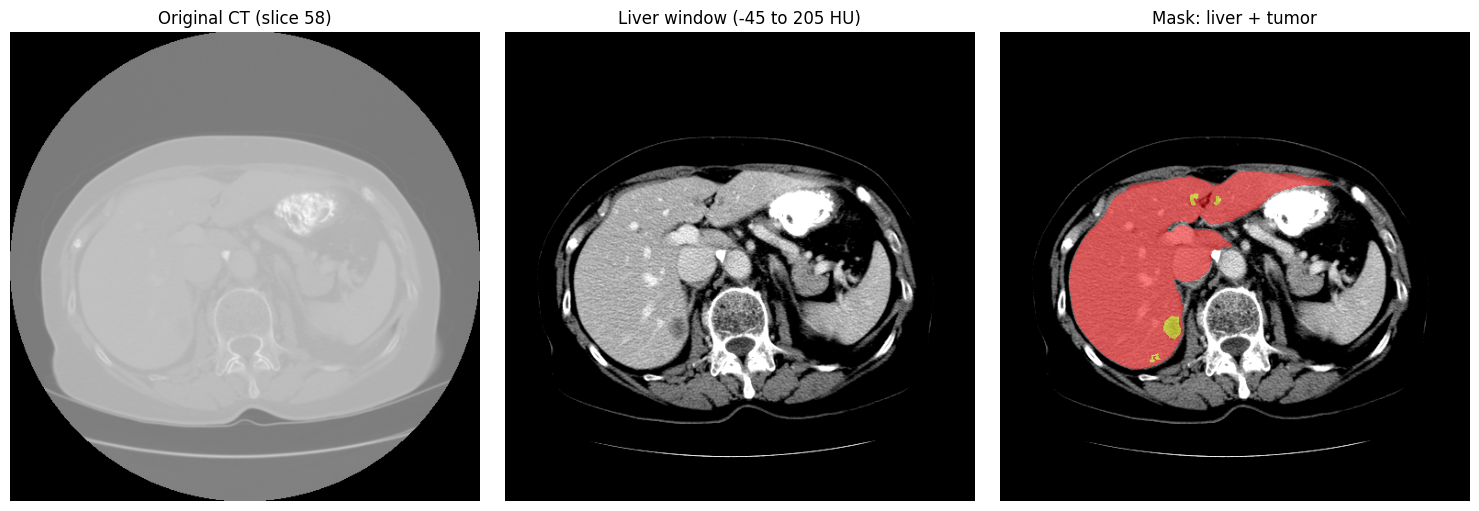

In [16]:
# cell 2.6 see the scan

import matplotlib.pyplot as plt

# find the slice with the most tumor
tumor_per_slice = (mask == 2).sum(axis=(0, 1))
if tumor_per_slice.max() > 0:
    z = int(np.argmax(tumor_per_slice))
else:
    z = int(np.argmax((mask == 1).sum(axis=(0, 1))))

ct_slice   = np.rot90(ct[:, :, z])
mask_slice = np.rot90(mask[:, :, z])
ct_window  = np.clip(ct_slice, -45, 205)   # the paper's liver window (WL 80, WW 250)

fig, ax = plt.subplots(1, 3, figsize=(15, 5))
ax[0].imshow(ct_slice, cmap='gray');  ax[0].set_title(f'Original CT (slice {z})')
ax[1].imshow(ct_window, cmap='gray'); ax[1].set_title('Liver window (-45 to 205 HU)')
ax[2].imshow(ct_window, cmap='gray')
ax[2].imshow(np.ma.masked_where(mask_slice == 0, mask_slice), cmap='autumn', alpha=0.5)
ax[2].set_title('Mask: liver + tumor')
for a in ax: a.axis('off')
plt.tight_layout()
plt.savefig('/content/drive/MyDrive/thesis/results/figures/step2_case0.png', dpi=150)
plt.show()